# Expense Claim Adjudication Crew
### Domain expert AI agents for travel and expense review

This notebook walks through the system end to end: the problem, the agent design, a
single claim reviewed in full, the evaluation against hand written labels, and the
honest limitations.

**Run order:** top to bottom. Nothing here needs an API key. The default engine is the
deterministic rule layer, so every number below is reproducible.

## 1. Setup

The only requirement for this notebook is pandas. The agent system itself uses the
standard library only.

In [1]:
import sys, json
from pathlib import Path
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.orchestrator import ExpenseReviewCrew, load_claims, load_employees, load_history
from src.policy_store import get_policy_store
from src import tools as T

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 70)
print("project root:", ROOT)

project root: /home/claude/expense-claim-agents


## 2. The business process

Travel and expense reimbursement is a high volume, low value, rule dense process. A
mid size consulting firm processes a few thousand claims a month. Each one is checked
against a policy document of roughly fifty clauses by a finance associate who has
about ninety seconds to spend on it.

Three things go wrong in practice:

1. **Leakage.** Over ceiling spend is approved because nobody recomputes a grade
   entitlement at 6pm on a Friday.
2. **Friction.** Legitimate claims are queried because a reviewer is unsure, and the
   employee spends a week chasing a reimbursement of two thousand rupees.
3. **No audit trail.** The reason a claim was approved exists only in the reviewer's
   head, so the control cannot be evidenced to an auditor.

This is a good fit for agents because the work is genuinely multi disciplinary. Policy
entitlement, indirect tax treatment and fraud risk are three different specialisms
that happen to look at the same document.

## 3. The policy, as a retrievable corpus

The policy is chunked by clause identifier rather than by token window, because a
clause is the natural unit of a finance rule and because every disallowance has to
cite one.

In [2]:
policy = get_policy_store()
print(f"{len(policy)} clauses indexed")

for clause, score in policy.search("can I claim wine on a client dinner bill", k=3):
    print(f"\n[{clause.clause_id}] {clause.section_title}  (similarity {score:.3f})")
    print("   ", clause.text[:200])

47 clauses indexed

[TE-03.3] Meals and Entertainment  (similarity 0.128)
    Client entertainment is reimbursable only where (a) a client attendee is named on the claim, (b) the engagement code is stated, and (c) pre approval from a B4 or above exists where the bill exceeds IN

[TE-01.4] Scope and Principles  (similarity 0.070)
    Where a client contract specifies a stricter expense term, the client term prevails and the difference is borne by the practice cost centre, not by the employee. ---

[TE-08.3] Approval Authority  (similarity 0.061)
    An expense already billed to and recovered from a client must be marked **client rechargeable** with the engagement code. Failure to mark a rechargeable expense is a control breach reported to the eng


## 4. The six agents

Each agent has a narrow charter. The charter is not decoration: it is injected into the
system prompt, and narrowness is the reason a small agent beats one large prompt that
tries to hold the whole policy at once.

Note the authority column. The Integrity analyst has the most alarming job and the
least power, by design.

In [3]:
crew = ExpenseReviewCrew(load_employees(), load_history())
print(crew.describe())

authority = pd.DataFrame([
    ["IntakeAgent",        "Evidence sufficiency, TE-05",        "can disallow an unevidenced line"],
    ["PolicyExpertAgent",  "Entitlements, ceilings, timelines",  "can disallow with a clause"],
    ["TaxComplianceAgent", "GSTIN validity, input tax credit",   "advises, rarely disallows"],
    ["FraudRiskAgent",     "Duplicates and integrity, TE-09",    "can escalate only, never reject"],
    ["AdjudicatorAgent",   "Outcome and approval routing",       "the only agent that sets an outcome"],
    ["CommunicatorAgent",  "Employee message and audit note",    "cannot change the outcome"],
], columns=["agent", "owns", "authority"])
authority

ExpenseReviewCrew
  model: offline (rule engine only)
  policy clauses indexed: 47
  IntakeAgent            Document and Data Steward
  PolicyExpertAgent      Policy Entitlement Expert
  TaxComplianceAgent     Indirect Tax and Input Credit Expert
  FraudRiskAgent         Integrity and Duplicate Risk Analyst
  AdjudicatorAgent       Claim Adjudicator and Approval Router
  CommunicatorAgent      Employee Communication Specialist


,agent,owns,authority
0,IntakeAgent,"Evidence sufficiency, TE-05",can disallow an unevidenced line
1,PolicyExpertAgent,"Entitlements, ceilings, timelines",can disallow with a clause
2,TaxComplianceAgent,"GSTIN validity, input tax credit","advises, rarely disallows"
3,FraudRiskAgent,"Duplicates and integrity, TE-09","can escalate only, never reject"
4,AdjudicatorAgent,Outcome and approval routing,the only agent that sets an outcome
5,CommunicatorAgent,Employee message and audit note,cannot change the outcome


## 5. The central design decision

**An agent never computes a rupee value.**

Arithmetic, date maths, checksum validation and threshold comparison all happen in
ordinary Python in `src/tools.py`, which is unit tested. The language model is used
for two things only: classifying free text whose meaning is genuinely ambiguous, and
writing the explanation.

A finance control that silently miscalculates is worse than no control, and a language
model cannot be audited the way a function with tests can.

In [4]:
# the tool layer is directly testable, which the agent layer is not
print("GSTIN checksum, valid:  ", T.validate_gstin("06AAJCM4321L1ZE"))
print("GSTIN checksum, tampered:", T.validate_gstin("06AAJCM4321L1ZK"))
print()
print("vendor normalisation:",
      T.normalize_vendor("Uber India Pvt. Ltd.") == T.normalize_vendor("  UBER-india "))

GSTIN checksum, valid:   {'valid': True, 'reason': 'ok', 'state_code': '06'}
GSTIN checksum, tampered: {'valid': False, 'reason': 'checksum mismatch, expected E', 'state_code': '06'}

vendor normalisation: True


## 6. One claim, reviewed in full

CLM-4015 is deliberately messy: a meal over the daily ceiling, and a cab line that
duplicates a line from an earlier claim.

In [5]:
claims = {c.claim_id: c for c in load_claims()}
claim = claims["CLM-4015"]
pd.DataFrame([l.to_dict() for l in claim.lines])[
    ["line_id", "category", "vendor", "expense_date", "city", "amount", "tax_amount"]]

,line_id,category,vendor,expense_date,city,amount,tax_amount
0,L1,hotel,Sofitel BKC,2026-10-06,Mumbai,8850.0,1350.0
1,L2,meals,Sofitel Pondichery,2026-10-06,Mumbai,2300.0,115.0
2,L3,cab,Uber India,2026-09-20,Bengaluru,740.0,0.0


In [6]:
d = crew.review(claim)

print(f"outcome      {d.outcome}")
print(f"claimed      INR {d.claimed_total:>10,.2f}")
print(f"disallowed   INR {d.disallowed_total:>10,.2f}")
print(f"payable      INR {d.approved_total:>10,.2f}")
print(f"risk         {d.risk_score}/100")
print(f"approver     {d.required_approver}")

outcome      ESCALATE
claimed      INR  11,890.00
disallowed   INR     300.00
payable      INR  11,590.00
risk         34/100
approver     Practice head (B4 or above)


### What each agent said

Notice that the duplicate finding disallows nothing. TE-09.1 defines a *suspected*
duplicate, and TE-11.4 forbids an automatic rejection on an integrity signal, so the
system records the amount at risk and hands the money decision to a person.

In [7]:
pd.DataFrame([{
    "agent": f.agent, "severity": f.severity, "clause": f.clause,
    "line": f.line_id, "disallows": f.disallowed_amount, "message": f.message,
} for f in d.findings])

,agent,severity,clause,line,disallows,message
0,FraudRiskAgent,integrity,TE-09.1,L3,0.0,Line L3 matches a line already submitted in claim CLM-0902: same v...
1,PolicyExpertAgent,violation,TE-03.1,L2,300.0,"Meals on 2026-10-06 in Mumbai total INR 2,300 against a daily ceil..."
2,TaxComplianceAgent,info,TE-06.3,L1,0.0,"Hotel invoice carries state code 27, outside the state of registra..."
3,TaxComplianceAgent,info,TE-06.2,L2,0.0,Food and beverage falls under blocked credit. INR 115 of tax is no...


In [8]:
pd.DataFrame([t.to_dict() for t in d.trace])

,agent,role,input_summary,output_summary,findings_count,duration_ms,used_llm
0,IntakeAgent,Document and Data Steward,"claim CLM-4015, 3 line(s), INR 11,890",no issues raised,0,0,False
1,PolicyExpertAgent,Policy Entitlement Expert,"claim CLM-4015, 3 line(s), INR 11,890",1 violation,1,0,False
2,TaxComplianceAgent,Indirect Tax and Input Credit Expert,"claim CLM-4015, 3 line(s), INR 11,890",2 info,2,0,False
3,FraudRiskAgent,Integrity and Duplicate Risk Analyst,"claim CLM-4015, 3 line(s), INR 11,890",1 integrity,1,0,False
4,AdjudicatorAgent,Claim Adjudicator and Approval Router,"claim CLM-4015, 3 line(s), INR 11,890",no issues raised,0,0,False


### The two artefacts that leave the system

Most expense automation stops at a decision. The expensive part is what the employee
reads next, so the Communicator writes both the employee message and the audit note
from the same decision object. Note that the employee is never told a line is
"suspicious"; an integrity flag is phrased as a query.

In [9]:
print(d.employee_message)
print("\n" + "=" * 78 + "\n")
print(d.audit_note)

Your claim needs a human reviewer before it can be settled.

Claim CLM-4015
Submitted value: INR 11,890.00
Not reimbursable: INR 300.00

Why:
  Query [TE-09.1]: Line L3 matches a line already submitted in claim CLM-0902: same vendor, same date, amount within one percent.
  Adjustment [TE-03.1]: Meals on 2026-10-06 in Mumbai total INR 2,300 against a daily ceiling of INR 2,000 for grade B3. Excess of INR 300 is disallowed.

Next step: Practice head (B4 or above) will review the points above. You may be asked for a short explanation or a clearer copy of a receipt. No action is needed from you until then.

Reviewed against policy v3.2 (effective 01 Apr 2026).


CLAIM CLM-4015 | EMP E1003 | ESCALATE | risk 34/100
Claimed 11,890.00 | Disallowed 300.00 | Payable 11,590.00 | Authority: Practice head (B4 or above)
  INTEGRITY TE-09.1   L3       DUP_HISTORY: Line L3 matches a line already submitted in claim CLM-0902: same vendor, same date, amount within one percent.
  VIOLATION TE-03.1   L2   

## 7. Evaluation

Forty four claims, each labelled by hand from the policy text **before** the system was
run. Labels produced by the system under test would measure nothing.

Two error classes are separated because they cost different things:

* **Leakage**: approving what should have been stopped. The company loses money.
* **Friction**: stopping what should have been approved. The employee loses trust.

In [10]:
import subprocess
out = subprocess.run([sys.executable, "-m", "eval.evaluate"], cwd=ROOT,
                     capture_output=True, text=True)
print(out.stdout[-2600:])

TE        disallow exp         0 got         0
  CLM-4012  tax_exceeds_gross                      exp ESCALATE        got ESCALATE        disallow exp         0 got         0
  CLM-4013  self_approval_conflict                 exp ESCALATE        got ESCALATE        disallow exp         0 got         0
  CLM-4014  entertainment_no_named_attendee        exp REJECT          got REJECT          disallow exp     5,600 got     5,600
  CLM-4015  mixed_breach_and_duplicate             exp ESCALATE        got ESCALATE        disallow exp       300 got       300
  CLM-5001  weekend_with_engagement_code           exp APPROVE         got APPROVE         disallow exp         0 got         0
  CLM-5002  small_value_no_invoice_needed          exp APPROVE         got APPROVE         disallow exp         0 got         0
  CLM-5003  round_amounts_are_advisory_only        exp APPROVE         got APPROVE         disallow exp         0 got         0
  CLM-5004  exactly_30_days_old                    exp AP

In [11]:
rep = json.loads((ROOT / "eval" / "results.json").read_text())
pd.DataFrame(rep["confusion"]).T

,APPROVE,PARTIAL_APPROVE,REJECT,ESCALATE
APPROVE,12,0,0,0
PARTIAL_APPROVE,0,11,0,0
REJECT,0,0,7,0
ESCALATE,0,0,0,14


## 8. The stress test matters more than the score

A perfect score on a benchmark written by the same person who wrote the rules measures
internal consistency, not accuracy. The property based stress test is the harder
check: it asserts invariants that must hold for *any* input, and it fuzzes three
hundred perturbed claims looking for a crash or an impossible total.

It found a real defect on its first run. Vendor names were compared with a bare
lowercase strip, so "uber  india" and "Uber India" were different merchants and a
duplicate slipped through. That is exactly the kind of gap a control is supposed to
close, and the label based benchmark never would have caught it.

In [12]:
out = subprocess.run([sys.executable, "-m", "eval.stress_test"], cwd=ROOT,
                     capture_output=True, text=True)
print(out.stdout[-1800:])

  I1 determinism over 44 claims, two passes      pass  0 mismatch(es)
  I2 disallowance rises with the amount          pass  final disallowance INR 10,500
  I3 exactly at ceiling is allowed               pass  APPROVE, disallowed 0.0
  I3 one rupee over is caught                    pass  disallowed INR 1.0
  I4 payable plus disallowed equals claimed      pass  
  I5 integrity flags never auto reject           pass  
  I6 duplicate survives case and spacing change  pass  outcome ESCALATE
  I7 every disallowance cites a clause           pass  
  Fuzz 300 perturbed claims, no crash            pass  0 crash(es)
  Fuzz 300 perturbed claims, no impossible total pass  0 impossible total(s)

10/10 invariants hold



## 9. Portfolio view

The same decisions aggregated the way a finance controller would want to see them.

In [13]:
decisions = crew.review_many(load_claims())
df = pd.DataFrame([{
    "claim": d.claim_id, "employee": d.employee_id, "outcome": d.outcome,
    "claimed": d.claimed_total, "disallowed": d.disallowed_total,
    "payable": d.approved_total, "risk": d.risk_score,
} for d in decisions])

summary = df.groupby("outcome").agg(
    claims=("claim", "count"), claimed=("claimed", "sum"),
    disallowed=("disallowed", "sum"), payable=("payable", "sum")).round(0)
display(summary)

total = df["claimed"].sum()
stp = df["outcome"].isin(["APPROVE", "PARTIAL_APPROVE"]).mean()
print(f"\ntotal claimed      INR {total:,.0f}")
print(f"total disallowed   INR {df['disallowed'].sum():,.0f} "
      f"({df['disallowed'].sum() / total:.1%} of value)")
print(f"straight through   {stp:.0%} of claims settled with no human")

,claims,claimed,disallowed,payable
outcome,,,,
APPROVE,12,95305.0,0.0,95305.0
ESCALATE,14,171152.0,300.0,170852.0
PARTIAL_APPROVE,11,84100.0,9330.0,74770.0
REJECT,7,22050.0,22050.0,0.0



total claimed      INR 372,607
total disallowed   INR 31,680 (8.5% of value)
straight through   52% of claims settled with no human


Text(0, 0.5, '')

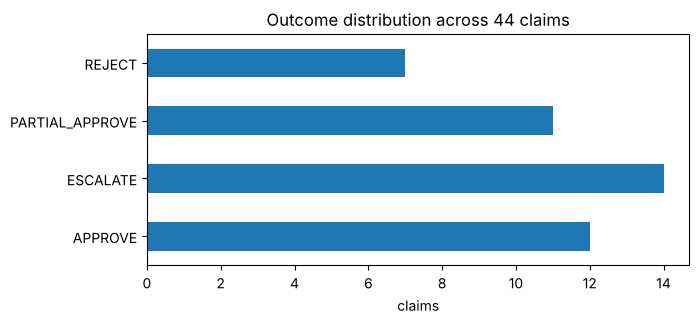

In [14]:
ax = df.groupby("outcome")["claim"].count().plot(
    kind="barh", title="Outcome distribution across 44 claims", figsize=(7, 3))
ax.set_xlabel("claims")
ax.set_ylabel("")

## 10. What this does not do

Stated plainly, because a project that claims no limitations has not been looked at
hard enough.

1. **The receipts are structured data, not images.** A production system needs OCR and
   document understanding on the actual PDF or photograph. Every field this system
   reads would, in reality, be an extraction with its own error rate, and that error
   rate would dominate everything measured here.
2. **The benchmark is synthetic and self authored.** Forty four claims written by the
   person who wrote the rules. Real claims are messier in ways that are hard to
   imagine in advance.
3. **The fraud detection is rule shaped.** It catches the patterns it was told about.
   A genuine fraud detection capability needs labelled historical outcomes and a model
   trained on them, which no student project has access to.
4. **The policy is fictional**, written for this project. A real deployment starts with
   a policy that contradicts itself in three places, which is a discovery problem
   before it is an engineering problem.
5. **Language model variance is unmeasured in the default path.** The offline engine is
   deterministic by design. Running with a live model would introduce variance in the
   free text classification, and that variance should be measured over repeated runs
   before anyone trusts it.

The honest summary: the rule engine is production shaped, the agent layer is a
credible design, and the evaluation proves consistency rather than real world accuracy.